# What Makes a Visual Novel Highly Rated? An Analysis of VNDB Data
**Data Analyst portfolio project — SQL, Python, Tableau**

**Questions**
1. How have visual novel releases and ratings changed over the years?
2. Do longer visual novels get higher ratings?
3. Which content tags (genres/themes) are linked to higher ratings?
4. How do TYPE-MOON titles (Fate/stay night, Tsukihime, Mahoyo) compare with the rest of the market?

**Data source:** [VNDB](https://vndb.org) (The Visual Novel Database) via its public API v2 (Kana), free for non-commercial use and
subject to the [VNDB Data License](https://vndb.org/d17). Data is crowdsourced by VNDB users.

**Scope:** visual novels with at least 50 user votes, so ratings are based on enough votes to be meaningful.

## 1. Setup

In [1]:
import time, json, sqlite3, requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8c8b85", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 10,
})
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#b4b2a9"

API = "https://api.vndb.org/kana/vn"
MIN_VOTES = 50

## 2. Fetch the data from the VNDB API
The API returns up to 100 results per page and allows up to 200 requests per 5 minutes, so the loop pauses between
requests and retries when throttled. If a page is too large ("Too much data selected"), it automatically requests fewer
results per page. **This takes a few minutes.**

In [2]:
FIELDS = ("id, title, released, olang, rating, average, votecount, length_minutes, length_votes, "
          "platforms, developers{name}, tags{name,category,rating,spoiler}")

def fetch_all(filters, fields=FIELDS, page_size=100, pause=1.6, max_pages=500):
    rows, page = [], 1
    while page <= max_pages:
        body = {"filters": filters, "fields": fields, "sort": "id",
                "results": page_size, "page": page}
        r = requests.post(API, json=body, timeout=60)
        if r.status_code == 429:                      # throttled: wait and retry
            print("Throttled, waiting 60s..."); time.sleep(60); continue
        if r.status_code == 400 and "Too much data" in r.text and page_size > 10:
            # smaller pages: restart counting so no rows are skipped or duplicated
            page_size //= 2; rows, page = [], 1
            print(f"Response too large, retrying with {page_size} results per page"); continue
        r.raise_for_status()
        data = r.json()
        rows.extend(data["results"])
        if page % 10 == 0:
            print(f"page {page}: {len(rows)} titles so far")
        if not data.get("more"):
            break
        page += 1
        time.sleep(pause)
    print(f"Done: {len(rows)} titles")
    return rows

raw = fetch_all(["votecount", ">=", MIN_VOTES])

# Save the raw data so you don't have to call the API again
with open("vndb_raw.json", "w") as f:
    json.dump(raw, f)

page 10: 1000 titles so far
page 20: 2000 titles so far
page 30: 3000 titles so far
page 40: 4000 titles so far
page 50: 5000 titles so far
Done: 5476 titles


**Already downloaded before?** Skip the cell above and load the saved file instead
(upload `vndb_raw.json` to Colab first).

In [3]:
# raw = json.load(open("vndb_raw.json"))

## 3. Clean and flatten into tables

In [18]:
def to_year(released):
    if isinstance(released, str) and released[:4].isdigit():
        return int(released[:4])
    return None

vn, tags, devs, plats = [], [], [], []
for v in raw:
    vid = v["id"]
    vtags = v.get("tags") or []
    # Adult flag: any sexual-content ("ero") tag applied with a strong rating (>= 1.5 on VNDB's 0-3 scale)
    adult = any(t.get("category") == "ero" and (t.get("rating") or 0) >= 1.5 for t in vtags)
    dev_names = [d.get("name") for d in (v.get("developers") or []) if d.get("name")]
    vn.append({
        "id": vid,
        "title": v.get("title"),
        "year": to_year(v.get("released")),
        "olang": v.get("olang"),
        "rating": v["rating"] / 10 if v.get("rating") is not None else None,     # 10-100 -> 1-10
        "average": v["average"] / 10 if v.get("average") is not None else None,
        "votecount": v.get("votecount"),
        "length_minutes": v.get("length_minutes"),
        "length_votes": v.get("length_votes"),
        "is_adult": int(adult),
        "is_typemoon": int(any("type-moon" in n.lower() for n in dev_names)),
    })
    for t in vtags:
        # content tags only, no spoilers, and only tags voted as clearly present (rating >= 1.5)
        if t.get("category") == "cont" and t.get("spoiler", 0) == 0 and (t.get("rating") or 0) >= 1.5:
            tags.append({"vn_id": vid, "tag": t.get("name"), "tag_rating": t.get("rating")})
    for n in dev_names:
        devs.append({"vn_id": vid, "developer": n})
    for p in v.get("platforms") or []:
        plats.append({"vn_id": vid, "platform": p})

df_vn, df_tags = pd.DataFrame(vn), pd.DataFrame(tags)
df_vn["year"] = df_vn["year"].astype("Int64")
df_devs, df_plats = pd.DataFrame(devs), pd.DataFrame(plats)

print("Visual novels:", len(df_vn))
print("Titles with adult content tags (kept in analysis):", df_vn["is_adult"].sum())
print("Missing values:")
print(df_vn[["year", "rating", "length_minutes"]].isna().sum())
df_vn.head()

Visual novels: 5476
Titles with adult content tags (kept in analysis): 4176
Missing values:
year                3
rating              0
length_minutes    716
dtype: int64


,id,title,year,olang,rating,average,votecount,length_minutes,length_votes,is_adult,is_typemoon
0,v1,Minna de Nyan Nyan,2003,ja,5.79,5.79,693,900.0,3,1,0
1,v2,Kana ~Imouto~,1999,ja,7.42,7.42,2053,651.0,54,1,0
2,v3,Utawarerumono,2002,ja,7.82,7.82,6133,2220.0,293,1,0
3,v4,CLANNAD,2004,ja,8.73,8.73,11622,4680.0,509,0,0
4,v5,Little Busters!,2007,ja,8.64,8.64,9403,4970.0,338,1,0


## 4. Load into a SQL database
The tables go into SQLite so the analysis can be written in SQL, the way it would be against a company database.
`analysis_vn` is a view with only the titles in scope (not adult, has a rating and a release year).

In [12]:
con = sqlite3.connect("vndb.db")
df_vn.to_sql("vn", con, if_exists="replace", index=False)
df_tags.to_sql("vn_tag", con, if_exists="replace", index=False)
df_devs.to_sql("vn_developer", con, if_exists="replace", index=False)
df_plats.to_sql("vn_platform", con, if_exists="replace", index=False)

con.executescript("""
DROP VIEW IF EXISTS analysis_vn;
CREATE VIEW analysis_vn AS
SELECT * FROM vn
WHERE rating IS NOT NULL AND year IS NOT NULL;
""")

def sql(q):
    return pd.read_sql(q, con)

sql("SELECT COUNT(*) AS titles_in_scope, ROUND(AVG(rating), 2) AS avg_rating, "
    "MIN(year) AS first_year, MAX(year) AS last_year FROM analysis_vn")

,titles_in_scope,avg_rating,first_year,last_year
0,5473,6.88,1983,2026


## 5. Q1 — How have releases and ratings changed over the years?

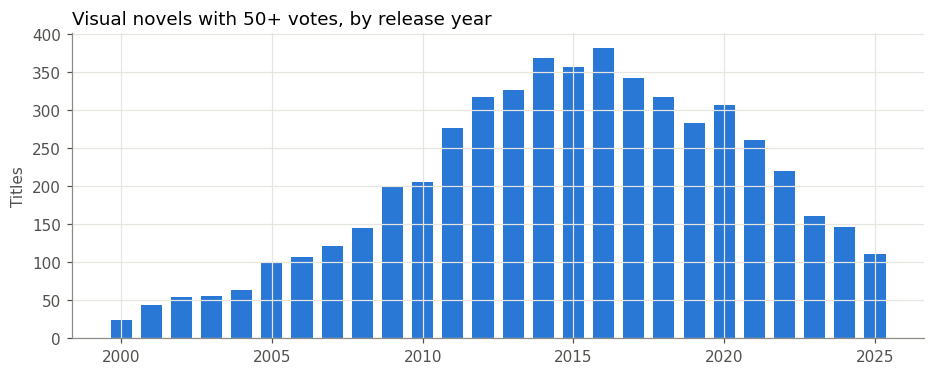

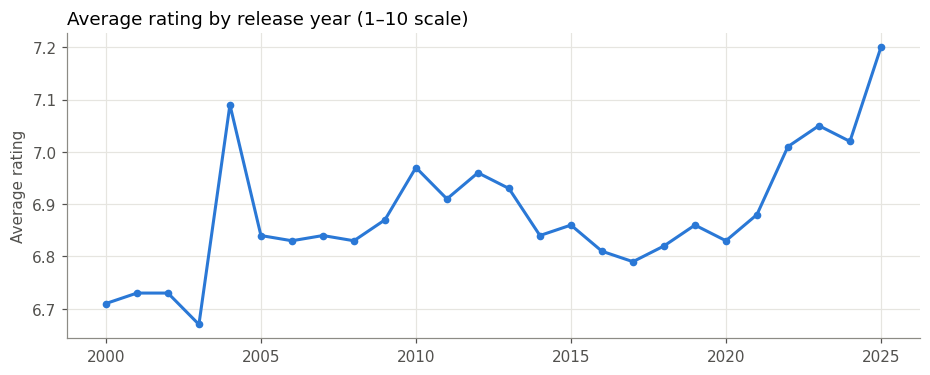

,year,titles,avg_rating
16,2016,382,6.81
17,2017,343,6.79
18,2018,317,6.82
19,2019,283,6.86
20,2020,307,6.83
21,2021,261,6.88
22,2022,220,7.01
23,2023,161,7.05
24,2024,146,7.02
25,2025,111,7.20


In [13]:
q1 = sql("""
SELECT year,
       COUNT(*)              AS titles,
       ROUND(AVG(rating), 2) AS avg_rating
FROM analysis_vn
WHERE year BETWEEN 2000 AND 2025
GROUP BY year
ORDER BY year
""")

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(q1["year"], q1["titles"], color=BLUE, width=0.7)
ax.set_title("Visual novels with 50+ votes, by release year", loc="left", fontsize=12)
ax.set_ylabel("Titles")
plt.show()

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(q1["year"], q1["avg_rating"], color=BLUE, linewidth=2, marker="o", markersize=4)
ax.set_title("Average rating by release year (1–10 scale)", loc="left", fontsize=12)
ax.set_ylabel("Average rating")
plt.show()
q1.tail(10)

## 6. Q2 — Do longer visual novels get higher ratings?
Play time comes from VNDB users' length votes. Only titles with at least 5 length votes are used.

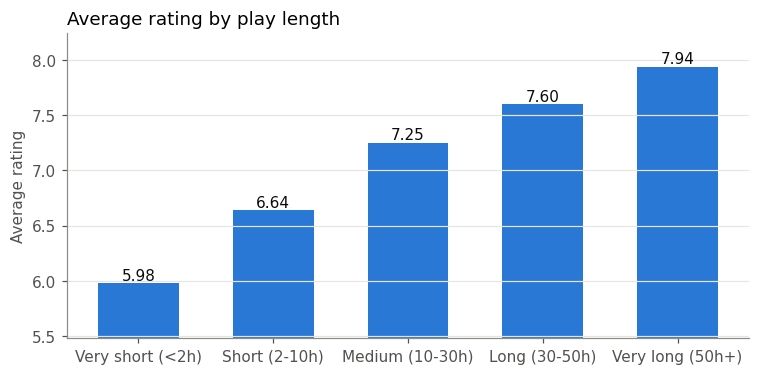

Spearman correlation between length and rating: 0.68


,length_group,titles,avg_rating
0,1. Very short (<2h),376,5.98
1,2. Short (2-10h),939,6.64
2,3. Medium (10-30h),869,7.25
3,4. Long (30-50h),372,7.60
4,5. Very long (50h+),144,7.94


In [14]:
q2 = sql("""
SELECT CASE
         WHEN length_minutes < 120   THEN '1. Very short (<2h)'
         WHEN length_minutes < 600   THEN '2. Short (2-10h)'
         WHEN length_minutes < 1800  THEN '3. Medium (10-30h)'
         WHEN length_minutes < 3000  THEN '4. Long (30-50h)'
         ELSE                             '5. Very long (50h+)'
       END                   AS length_group,
       COUNT(*)              AS titles,
       ROUND(AVG(rating), 2) AS avg_rating
FROM analysis_vn
WHERE length_minutes IS NOT NULL AND length_votes >= 5
GROUP BY length_group
ORDER BY length_group
""")

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(q2["length_group"].str[3:], q2["avg_rating"], color=BLUE, width=0.6)
for i, (v, n) in enumerate(zip(q2["avg_rating"], q2["titles"])):
    ax.text(i, v + 0.03, f"{v:.2f}", ha="center", color="#0b0b0b")
ax.set_ylim(q2["avg_rating"].min() - 0.5, q2["avg_rating"].max() + 0.3)
ax.set_title("Average rating by play length", loc="left", fontsize=12)
ax.set_ylabel("Average rating")
ax.grid(axis="x", visible=False)
plt.show()

corr = sql("SELECT length_minutes, rating FROM analysis_vn WHERE length_minutes IS NOT NULL AND length_votes >= 5")
print(f"Spearman correlation between length and rating: {corr.corr(method='spearman').iloc[0, 1]:.2f}")
q2

## 7. Q3 — Which content tags are linked to higher ratings?
Only tags that appear on at least 100 titles are compared, so averages are not driven by a handful of titles.

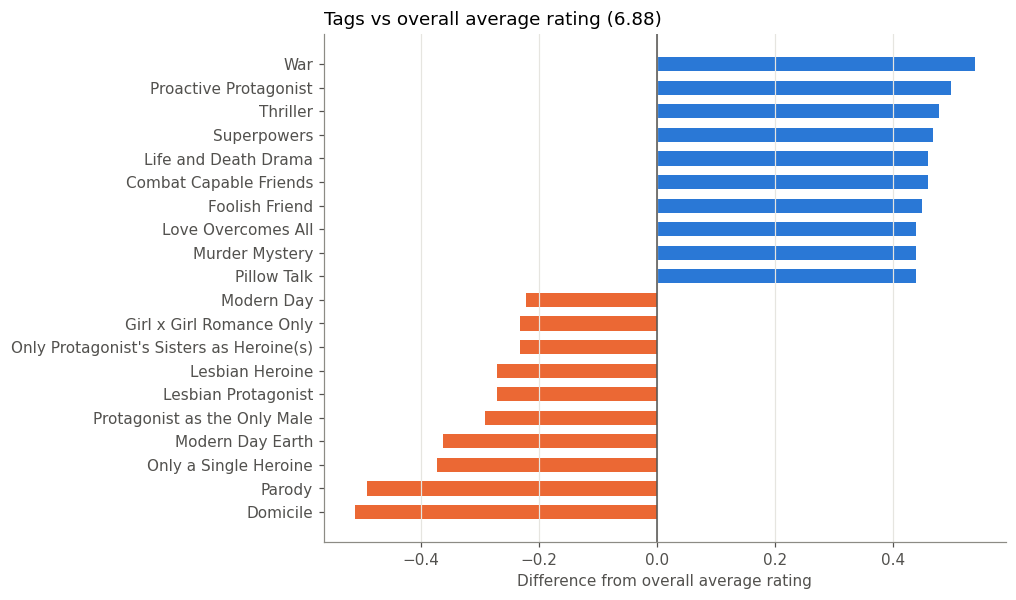

Highest-rated tags:


,tag,titles,avg_rating
0,War,135,7.42
1,Proactive Protagonist,476,7.38
2,Thriller,117,7.36
3,Superpowers,122,7.35
4,Life and Death Drama,235,7.34
5,Combat Capable Friends,192,7.34
6,Foolish Friend,161,7.33
7,Pillow Talk,117,7.32
8,Murder Mystery,136,7.32
9,Love Overcomes All,274,7.32


Lowest-rated tags:


,tag,titles,avg_rating
212,Modern Day,259,6.66
213,Only Protagonist's Sisters as Heroine(s),106,6.65
214,Girl x Girl Romance Only,172,6.65
215,Lesbian Protagonist,108,6.61
216,Lesbian Heroine,144,6.61
217,Protagonist as the Only Male,174,6.59
218,Modern Day Earth,111,6.52
219,Only a Single Heroine,748,6.51
220,Parody,111,6.39
221,Domicile,137,6.37


In [15]:
q3 = sql("""
SELECT t.tag,
       COUNT(*)                 AS titles,
       ROUND(AVG(v.rating), 2)  AS avg_rating
FROM vn_tag t
JOIN analysis_vn v ON v.id = t.vn_id
GROUP BY t.tag
HAVING COUNT(*) >= 100
ORDER BY avg_rating DESC
""")
overall = sql("SELECT AVG(rating) AS r FROM analysis_vn")["r"][0]

top, bottom = q3.head(10), q3.tail(10)
show = pd.concat([top, bottom]).drop_duplicates("tag").sort_values("avg_rating")

fig, ax = plt.subplots(figsize=(8, 6))
colors = [BLUE if r >= overall else ORANGE for r in show["avg_rating"]]
ax.barh(show["tag"], show["avg_rating"] - overall, color=colors, height=0.6)
ax.axvline(0, color="#52514e", linewidth=1)
ax.set_title(f"Tags vs overall average rating ({overall:.2f})", loc="left", fontsize=12)
ax.set_xlabel("Difference from overall average rating")
ax.grid(axis="y", visible=False)
plt.show()
print("Highest-rated tags:"); display(top)
print("Lowest-rated tags:"); display(bottom)

## 8. Q4 — How do TYPE-MOON titles compare?

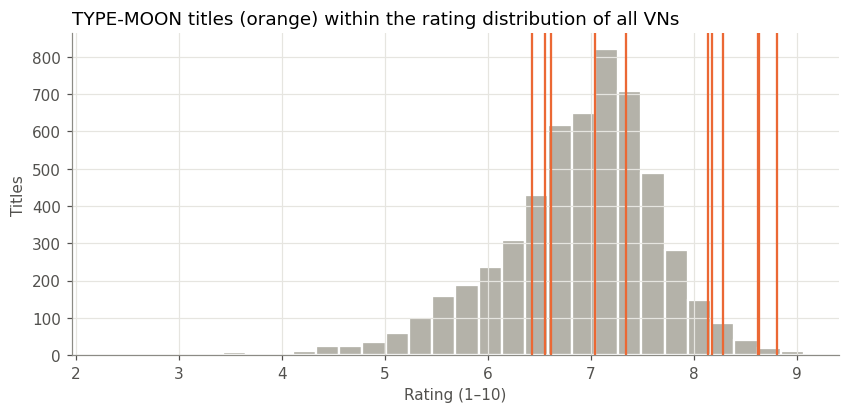

11 TYPE-MOON titles found (developer name contains 'TYPE-MOON').


,title,year,rating,votecount,rating_percentile
0,Tsukihime -A piece of blue glass moon-,2021,8.81,3117,99.8
1,Fate/stay night,2004,8.63,19548,99.5
2,Mahoutsukai no Yoru,2012,8.62,5798,99.5
3,Fate/EXTRA CCC,2013,8.28,826,98.1
4,Tsukihime,2000,8.18,11762,97.3
5,Fate/hollow ataraxia,2005,8.14,5951,96.8
6,Kagetsu Tooya,2001,7.34,3581,71.9
7,Fate/EXTRA,2010,7.04,2550,52.4
8,Tsukihime PLUS-DISC,2001,6.61,2504,30.1
9,Fate/EXTELLA,2016,6.55,911,27.8


In [16]:
q4 = sql("""
WITH ranked AS (
  SELECT id, title, year, rating, votecount, is_typemoon,
         PERCENT_RANK() OVER (ORDER BY rating) AS pct_rank
  FROM analysis_vn
)
SELECT title, year, rating, votecount,
       ROUND(pct_rank * 100, 1) AS rating_percentile
FROM ranked
WHERE is_typemoon = 1
ORDER BY rating DESC
""")

all_ratings = sql("SELECT rating FROM analysis_vn")["rating"]
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(all_ratings, bins=30, color=GREY, edgecolor="white", linewidth=1.5)
for _, r in q4.iterrows():
    ax.axvline(r["rating"], color=ORANGE, linewidth=1.5)
ax.set_title("TYPE-MOON titles (orange) within the rating distribution of all VNs", loc="left", fontsize=12)
ax.set_xlabel("Rating (1–10)")
ax.set_ylabel("Titles")
plt.show()
print(f"{len(q4)} TYPE-MOON titles found (developer name contains 'TYPE-MOON').")
q4

## 9. Export for Tableau

In [17]:
sql("SELECT * FROM analysis_vn").to_csv("vn_analysis.csv", index=False)
sql("""SELECT t.vn_id, t.tag, v.rating, v.year FROM vn_tag t
       JOIN analysis_vn v ON v.id = t.vn_id""").to_csv("vn_tags.csv", index=False)
print("Saved vn_analysis.csv and vn_tags.csv. Download them from the Files panel on the left.")

Saved vn_analysis.csv and vn_tags.csv. Download them from the Files panel on the left.


## 10. Key findings

**Scope:** 5,473 visual novels with 50+ votes on VNDB; overall average rating 6.88 (1–10 scale).

1. **Releases & ratings over time:** The number of titles reaching 50+ votes peaked in 2016 (382) and fell to 111 in 2025, while average ratings rose from 6.83 in 2020 to 7.20 in 2025. Both trends are partly a recency effect: newer titles have had less time to collect votes, so the recent titles that already reach 50 votes tend to be the most popular and best received.
2. **Length vs rating:** Longer visual novels are rated clearly higher, rising steadily from 5.98 for very short titles (<2h) to 7.94 for very long ones (50h+). The Spearman correlation between play length and rating is 0.68, the strongest relationship in this analysis.
3. **Tags:** Story-driven, high-stakes themes score highest, such as War (7.42), Thriller (7.36), and Life and Death Drama (7.34). Slice-of-life and lighter themes score lowest, such as Only a Single Heroine (6.51), Parody (6.39), and Domicile (6.37). The gap is about ±0.5 points from the overall average.
4. **TYPE-MOON:** 6 of 11 TYPE-MOON titles rank in the top 3% of all visual novels, led by Tsukihime -A piece of blue glass moon- (8.81, 99.8th percentile), Fate/stay night (8.63, the most-voted with 19,548 votes), and Mahoutsukai no Yoru (8.62). Fan discs and action spin-offs (Tsukihime PLUS-DISC, Fate/EXTELLA) sit below the median, suggesting TYPE-MOON's strength lies in its long, story-driven main visual novels.

**Business takeaway:** Among core visual novel fans, long, story-heavy titles with high-stakes conflict earn the best reception. That matches the profile of TYPE-MOON's top-rated works.

**Limitations**
- VNDB is crowdsourced, and its users are mostly English-speaking enthusiasts, so ratings reflect that community.
- Only titles with 50+ votes are included, which favours better-known titles and makes recent years look smaller and higher-rated.
- Findings show correlation, not causation: longer or war-themed games are not automatically better.
- Titles with adult-only releases are included because VNDB groups all-ages and adult releases under one entry; the analysis uses only aggregate ratings, not images or descriptions.